# DATA 266 Homework: GAN Concepts and Autoencoders on FashionMNIST

In [ ]:
# Required personal parameters and reproducibility setup
SID4 = 2046
SEED = SID4
SLICE = SID4 % 1000
HP_ID = SID4 % 6
CLS_A = SID4 % 10
CLS_B = (CLS_A + 1 + ((SID4 // 10) % 9)) % 10

print(f"SID4 = {SID4}")
print(f"SEED = {SEED}")
print(f"SLICE = {SLICE}")
print(f"HP_ID = {HP_ID}")
print(f"CLS_A = {CLS_A}")
print(f"CLS_B = {CLS_B}")
assert (SID4, SEED, SLICE, HP_ID, CLS_A, CLS_B) == (2046, 2046, 46, 0, 6, 3)


SID4 = 2046
SEED = 2046
SLICE = 46
HP_ID = 0
CLS_A = 6
CLS_B = 3


## 1. Fundamental Architecture of a GAN

A Generative Adversarial Network, or GAN, consists of two neural networks that are trained against each other: a **generator** and a **discriminator**.

The **generator** is responsible for creating synthetic data. It starts with a random noise vector and transforms it through a neural network to produce an output that resembles samples from the real training data. For an image dataset, for example, the generator learns to turn random noise into realistic looking images. Initially, these generated images are usually poor, but they improve as training progresses.

The **discriminator** acts as a classifier. It receives both real samples from the training dataset and fake samples produced by the generator, and tries to determine whether each sample is real or generated. Its output represents how likely it believes a sample came from the real data distribution.

During training, the two networks have opposing objectives. The discriminator is trained to correctly distinguish real samples from generated ones. The generator is trained to produce samples that are convincing enough to fool the discriminator. As the discriminator becomes better at identifying fake samples, the generator receives stronger feedback about where its generated data differs from real data and adjusts its parameters accordingly.

This creates an **adversarial training process**. The discriminator can be viewed as continuously improving its ability to detect counterfeits, while the generator continuously improves its ability to create them. Neither network is trained independently because improvement in one network changes the learning problem faced by the other.

The theoretical goal is for the generator to learn the underlying probability distribution of the real training data. In the ideal equilibrium, the generated distribution matches the real data distribution closely enough that the discriminator can no longer reliably distinguish between them. At this point, the discriminator would assign approximately a **50% probability** to whether a sample is real or generated, meaning that the generator has successfully learned to produce samples that are statistically indistinguishable from the real data.


## 2. Mode Collapse

**Mode collapse** is a common failure in GAN training where the generator learns to produce only a small variety of outputs instead of representing the full diversity of the training data. For example, if a GAN is trained on FashionMNIST, it might discover that generating a particular type of shoe consistently fools the discriminator. Instead of learning to generate shirts, dresses, bags, shoes, and other items, it may repeatedly generate similar looking shoes.

This happens because the generator is rewarded for **fooling the discriminator**, not directly for producing diverse outputs. If the generator discovers a small set of outputs that currently work well against the discriminator, it can repeatedly produce variations of those outputs. GAN training is also unstable because the generator and discriminator are continuously changing in response to each other. If one network becomes much stronger than the other, the training signal can become weak or unstable, making collapse more likely.

One technique used to reduce mode collapse is **minibatch discrimination**. A normal discriminator evaluates samples mostly independently, which can make it difficult to recognize that the generator is repeatedly producing nearly identical outputs. Minibatch discrimination allows the discriminator to compare samples within the same batch. If many generated samples are extremely similar, the discriminator can recognize this lack of diversity and classify them as fake. The generator is therefore encouraged to produce a wider variety of outputs.

Another approach is the **Wasserstein GAN, or WGAN**. The original GAN objective can provide poor or unstable gradients when the real and generated distributions have little overlap, especially early in training. WGAN replaces the original divergence based objective with the Wasserstein distance, which provides a smoother and more informative measure of how far the generated distribution is from the real distribution. This generally gives the generator more useful gradients and makes training more stable. Later approaches such as WGAN GP further improve this by using a gradient penalty to enforce the constraints required by the Wasserstein objective.

Both approaches address mode collapse differently. Minibatch discrimination directly encourages diversity by helping the discriminator detect repetitive outputs, while WGAN improves the optimization process so that the generator receives more stable feedback and is less likely to settle on only a few successful outputs.




## 3. Significant GAN Variants

#### DCGAN

**Deep Convolutional GAN, or DCGAN**, was introduced to make GANs more effective and stable when generating images. The original GAN architecture relied mainly on fully connected layers, which do not take advantage of the spatial structure present in images.

DCGAN replaces these layers with **convolutional neural networks**. The discriminator uses strided convolutions to learn spatial features from images, while the generator uses transposed convolutions to progressively transform a latent vector into an image. It also introduced architectural practices such as batch normalization and carefully chosen activation functions to improve training stability.

The main contribution of DCGAN was showing that GANs could learn useful hierarchical image features and generate significantly better images by designing the generator and discriminator specifically for visual data.


#### Conditional GAN

A standard GAN gives the user little control over what the generator produces because generation depends mainly on random noise. A **Conditional GAN, or cGAN**, addresses this limitation by giving both the generator and discriminator additional information about the desired output.

This information can be a class label or another form of context. For example, when training on FashionMNIST, instead of simply asking the generator to produce a random clothing image, we could provide the label for **Dress** and ask it to generate an image belonging specifically to that class.

The generator therefore learns a conditional distribution rather than only the overall data distribution. The discriminator also receives the condition so that it evaluates not only whether an image looks real, but whether it is consistent with the requested condition. This makes GAN generation much more controllable and is useful when specific categories or attributes need to be generated.


#### CycleGAN

**CycleGAN** addresses a different problem: translating images between two domains when paired examples are not available. Traditional supervised image translation usually requires corresponding pairs, such as the exact same scene represented in two different styles. Collecting such paired datasets can be difficult or impossible.

CycleGAN instead learns using **unpaired datasets**. It uses two generators and two discriminators. One generator learns a transformation from domain A to domain B, while the second learns the reverse transformation from B to A.

Its major innovation is **cycle consistency loss**. If an image is transformed from A to B and then transformed back from B to A, the final image should resemble the original. For example, if the model converts a horse image into a zebra and then converts that generated zebra back into a horse, the reconstructed image should remain close to the original horse.

This cycle consistency constraint prevents the generators from making arbitrary transformations while still allowing the model to learn without paired examples. As a result, CycleGAN can perform tasks such as changing seasons, transferring artistic styles, or translating between visual domains using independently collected datasets.

## 2. FC Autoencoder and Variational Autoencoder on FashionMNIST

For the experimental portion of this assignment, I train and evaluate two autoencoder architectures on FashionMNIST: a fully connected autoencoder and a variational autoencoder.

The experiments use my assigned reproducibility parameters from SID4 = 2046. The same train, validation, and test data setup is used for both models so their results can be compared consistently.

In [23]:
import random
import sys
import platform
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

import torch
from torch import nn, optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets
from torchvision.transforms import v2 as T

from tqdm.auto import tqdm

SID4 = 2046
SEED = 2046
SLICE = 46
HP_ID = 0
CLS_A = 6
CLS_B = 3

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("SID4:", SID4)
print("SEED:", SEED)
print("SLICE:", SLICE)
print("HP_ID:", HP_ID)
print("CLS_A:", CLS_A)
print("CLS_B:", CLS_B)
print("Device:", device)
print("PyTorch:", torch.__version__)
print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())

SID4: 2046
SEED: 2046
SLICE: 46
HP_ID: 0
CLS_A: 6
CLS_B: 3
Device: cpu
PyTorch: 2.11.0+cpu
Python: 3.13.16
Platform: Linux-6.6.122+-x86_64-with-glibc2.39


### FashionMNIST Dataset

FashionMNIST contains 28 × 28 grayscale images from 10 clothing categories. Each image is converted to a floating point tensor with pixel values in the range [0, 1] and flattened from 28 × 28 into a 784 dimensional vector for the fully connected networks.

I use the assigned SEED for the train and validation split and for DataLoader shuffling so that the experiment is reproducible.

In [24]:
transform = T.Compose([
    T.ToImage(),
    T.ToDtype(torch.float32, scale=True),
    T.Lambda(lambda x: torch.flatten(x))
])

full_train = datasets.FashionMNIST(
    root="data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.FashionMNIST(
    root="data",
    train=False,
    download=True,
    transform=transform
)

print("Full training set:", len(full_train))
print("Test set:", len(test_dataset))
print("Input shape:", full_train[0][0].shape)

Full training set: 60000
Test set: 10000
Input shape: torch.Size([784])


In [25]:
train_dataset, val_dataset = random_split(
    full_train,
    [54000, 6000],
    generator=torch.Generator().manual_seed(SEED)
)

BATCH_SIZE = 256

loader_generator = torch.Generator().manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=loader_generator
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

class_names = full_train.classes

print("Training examples:", len(train_dataset))
print("Validation examples:", len(val_dataset))
print("Test examples:", len(test_dataset))
print("Number of classes:", len(class_names))
print("CLS_A:", CLS_A, class_names[CLS_A])
print("CLS_B:", CLS_B, class_names[CLS_B])

Training examples: 54000
Validation examples: 6000
Test examples: 10000
Number of classes: 10
CLS_A: 6 Shirt
CLS_B: 3 Dress


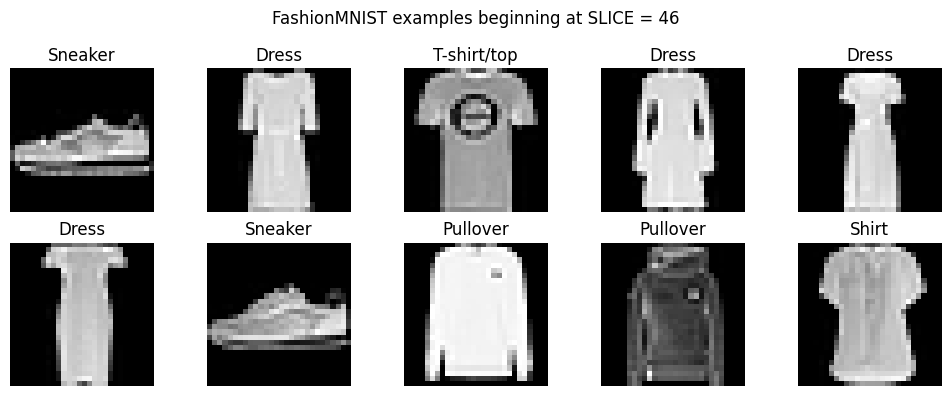

In [26]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))

for j, ax in enumerate(axes.flat):
    image, label = full_train[SLICE + j]

    ax.imshow(image.reshape(28, 28), cmap="gray")
    ax.set_title(class_names[label])
    ax.axis("off")

plt.suptitle(f"FashionMNIST examples beginning at SLICE = {SLICE}")
plt.tight_layout()
plt.show()

In [27]:
x_batch, y_batch = next(iter(train_loader))

print("Batch image shape:", x_batch.shape)
print("Batch label shape:", y_batch.shape)
print("Pixel minimum:", x_batch.min().item())
print("Pixel maximum:", x_batch.max().item())

assert x_batch.shape[1] == 784
assert 0.0 <= x_batch.min().item()
assert x_batch.max().item() <= 1.0

print("Dataset pipeline checks passed.")

Batch image shape: torch.Size([256, 784])
Batch label shape: torch.Size([256])
Pixel minimum: 0.0
Pixel maximum: 1.0
Dataset pipeline checks passed.


### Fully Connected Autoencoder

The fully connected autoencoder learns a compressed representation of each FashionMNIST image. The encoder reduces the 784 dimensional input to a smaller latent representation, while the decoder reconstructs the original image from that representation.

Because the input pixels are scaled to the range [0, 1], the decoder uses a sigmoid activation at its output. The model is trained by minimizing mean squared reconstruction error between the original and reconstructed images.


In [28]:
class FCAutoencoder(nn.Module):
    def __init__(self, latent_dim=32):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, latent_dim)
        )

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Sigmoid()
        )

    def forward(self, x):
        z = self.encoder(x)
        reconstruction = self.decoder(z)
        return reconstruction


LATENT_DIM = 32

fc_ae = FCAutoencoder(latent_dim=LATENT_DIM).to(device)

print(fc_ae)

total_params = sum(p.numel() for p in fc_ae.parameters())
trainable_params = sum(
    p.numel() for p in fc_ae.parameters() if p.requires_grad
)

print()
print("Latent dimension:", LATENT_DIM)
print("Total parameters:", f"{total_params:,}")
print("Trainable parameters:", f"{trainable_params:,}")

FCAutoencoder(
  (encoder): Sequential(
    (0): Linear(in_features=784, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=32, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=32, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=784, bias=True)
    (5): Sigmoid()
  )
)

Latent dimension: 32
Total parameters: 476,720
Trainable parameters: 476,720


In [29]:
x_batch, _ = next(iter(train_loader))
x_batch = x_batch.to(device)

with torch.no_grad():
    reconstruction = fc_ae(x_batch)

print("Input shape:", x_batch.shape)
print("Reconstruction shape:", reconstruction.shape)

assert reconstruction.shape == x_batch.shape
assert torch.isfinite(reconstruction).all()

print("FC Autoencoder forward pass successful.")

Input shape: torch.Size([256, 784])
Reconstruction shape: torch.Size([256, 784])
FC Autoencoder forward pass successful.


#### Training Configuration

The FC Autoencoder is optimized with Adam using mean squared error as the reconstruction loss. Validation loss is measured after every epoch using the held out validation set.

The same validation data will later be used while training the VAE so that the two models are evaluated under a consistent experimental setup.

In [30]:
FC_LR = 1e-3
FC_EPOCHS = 15

fc_criterion = nn.MSELoss()
fc_optimizer = optim.Adam(fc_ae.parameters(), lr=FC_LR)

print("Optimizer: Adam")
print("Learning rate:", FC_LR)
print("Epochs:", FC_EPOCHS)
print("Batch size:", BATCH_SIZE)
print("Loss: Mean Squared Error")

Optimizer: Adam
Learning rate: 0.001
Epochs: 15
Batch size: 256
Loss: Mean Squared Error


In [31]:
def train_fc_epoch(model, loader, optimizer, criterion, device):
    model.train()

    running_loss = 0.0
    total_samples = 0

    for x, _ in loader:
        x = x.to(device)

        optimizer.zero_grad()

        reconstruction = model(x)
        loss = criterion(reconstruction, x)

        loss.backward()
        optimizer.step()

        batch_size = x.size(0)
        running_loss += loss.item() * batch_size
        total_samples += batch_size

    return running_loss / total_samples


@torch.no_grad()
def evaluate_fc(model, loader, criterion, device):
    model.eval()

    running_loss = 0.0
    total_samples = 0

    for x, _ in loader:
        x = x.to(device)

        reconstruction = model(x)
        loss = criterion(reconstruction, x)

        batch_size = x.size(0)
        running_loss += loss.item() * batch_size
        total_samples += batch_size

    return running_loss / total_samples

In [32]:
fc_train_losses = []
fc_val_losses = []

best_fc_val_loss = float("inf")
best_fc_state = None

for epoch in range(1, FC_EPOCHS + 1):
    train_loss = train_fc_epoch(
        fc_ae,
        train_loader,
        fc_optimizer,
        fc_criterion,
        device
    )

    val_loss = evaluate_fc(
        fc_ae,
        val_loader,
        fc_criterion,
        device
    )

    fc_train_losses.append(train_loss)
    fc_val_losses.append(val_loss)

    if val_loss < best_fc_val_loss:
        best_fc_val_loss = val_loss

        best_fc_state = {
            key: value.detach().cpu().clone()
            for key, value in fc_ae.state_dict().items()
        }

    print(
        f"Epoch {epoch:02d}/{FC_EPOCHS} "
        f"Train Loss: {train_loss:.6f} "
        f"Val Loss: {val_loss:.6f}"
    )

fc_ae.load_state_dict(best_fc_state)

print()
print("Best validation loss:", f"{best_fc_val_loss:.6f}")

Epoch 01/15 Train Loss: 0.051892 Val Loss: 0.028535
Epoch 02/15 Train Loss: 0.024799 Val Loss: 0.022118
Epoch 03/15 Train Loss: 0.020751 Val Loss: 0.018953
Epoch 04/15 Train Loss: 0.018391 Val Loss: 0.017470
Epoch 05/15 Train Loss: 0.017191 Val Loss: 0.016595
Epoch 06/15 Train Loss: 0.016393 Val Loss: 0.015949
Epoch 07/15 Train Loss: 0.015776 Val Loss: 0.015470
Epoch 08/15 Train Loss: 0.015262 Val Loss: 0.014844
Epoch 09/15 Train Loss: 0.014755 Val Loss: 0.014407
Epoch 10/15 Train Loss: 0.014354 Val Loss: 0.013993
Epoch 11/15 Train Loss: 0.013988 Val Loss: 0.013618
Epoch 12/15 Train Loss: 0.013626 Val Loss: 0.013250
Epoch 13/15 Train Loss: 0.013247 Val Loss: 0.013069
Epoch 14/15 Train Loss: 0.012915 Val Loss: 0.012677
Epoch 15/15 Train Loss: 0.012637 Val Loss: 0.012408

Best validation loss: 0.012408


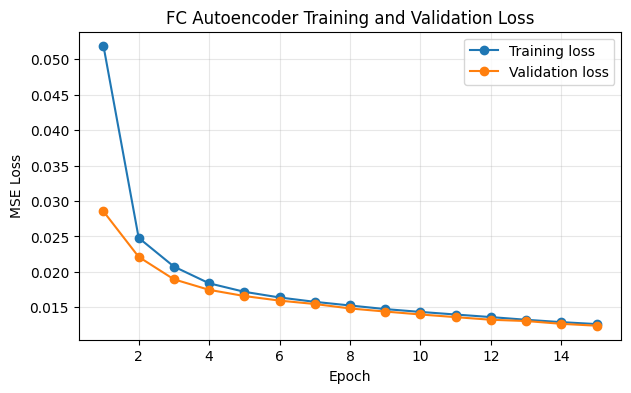

In [33]:
plt.figure(figsize=(7, 4))

epochs = range(1, FC_EPOCHS + 1)

plt.plot(epochs, fc_train_losses, marker="o", label="Training loss")
plt.plot(epochs, fc_val_losses, marker="o", label="Validation loss")

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("FC Autoencoder Training and Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [34]:
fc_test_loss = evaluate_fc(
    fc_ae,
    test_loader,
    fc_criterion,
    device
)

print("FC Autoencoder results")
print("Best validation MSE:", f"{best_fc_val_loss:.6f}")
print("Test MSE:", f"{fc_test_loss:.6f}")

FC Autoencoder results
Best validation MSE: 0.012408
Test MSE: 0.012584


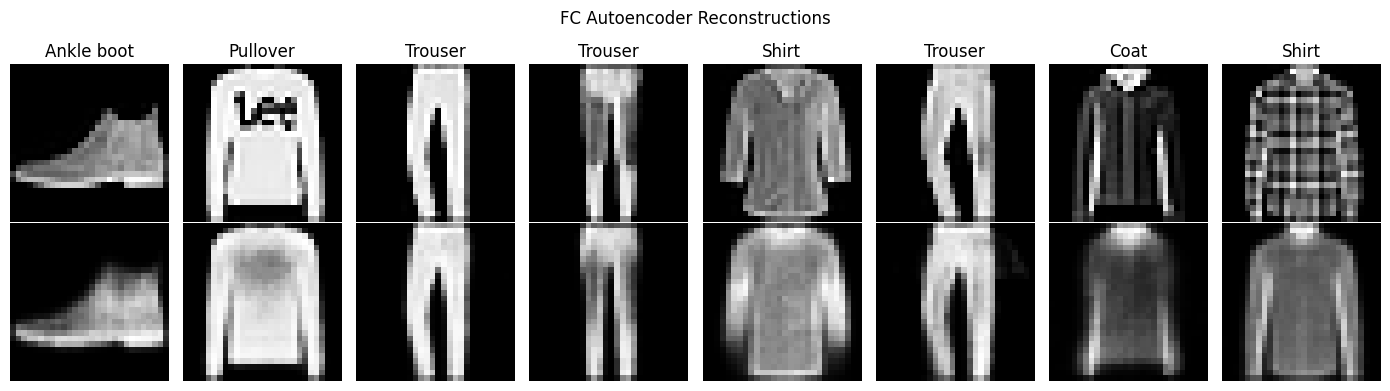

In [35]:
fc_ae.eval()

test_images, test_labels = next(iter(test_loader))
test_images_device = test_images.to(device)

with torch.no_grad():
    reconstructed_images = fc_ae(test_images_device).cpu()

n_examples = 8

fig, axes = plt.subplots(2, n_examples, figsize=(14, 4))

for i in range(n_examples):
    axes[0, i].imshow(
        test_images[i].reshape(28, 28),
        cmap="gray"
    )
    axes[0, i].set_title(class_names[test_labels[i]])
    axes[0, i].axis("off")

    axes[1, i].imshow(
        reconstructed_images[i].reshape(28, 28),
        cmap="gray"
    )
    axes[1, i].axis("off")

axes[0, 0].set_ylabel("Original")
axes[1, 0].set_ylabel("Reconstructed")

plt.suptitle("FC Autoencoder Reconstructions")
plt.tight_layout()
plt.show()